**Що було в Lab 1 і 2**

Я досліджував RCR, який щукається за формолою

$$\text{Repeat Customer Rate}=\frac{\text{Number of Return Customers}}{\text{Total Number of Customers}}$$


**Вхідні дані:**
* Q = 305
* N = 1000



**Гіпотези були:**
* $H_0$: $μ = 0.28$
* $H_1$: $μ > 0.28$

**Вибір сторони і alpha:**
* alpha = 0.05
* Тест правосторонній, оскільки нас цікавить збільшення


**Результати тесту:**

* Estimate: 0.305
* p-value : 0.043 <= 0.05
* Critcal Value : 304
* Power = 0.96
* Достатня N = 551 при MDE = 0.05 для $Power \ge 0.8$
* Мінімальне альтернативне mu = 0.32 при N = 1000 для $Power ≥ 0.8$
* Confidence Interval : 0.281 -- 1.0


**Формування гіпотез:**
<div align="center">$H_0$: $p_0$ = $p_1$ &emsp; vs &emsp; $H_0$: $p_0$ < $p_1$</div>

$p_0$ - конверсія для групи A для якої все без змін, акція для них не діє

$p_1$ - конверсія для групи B для якої акція діє

$μ_0$ не є гарним показником для порівняння, оскільки у бізнеса може бути сезоність та можуть бути інші фактори, які роблять поточну конверсія іншою.
Щоб цього уникнути роблять двох вибірковий тест, де одна група без змін показую поточну конверсію, а друга показує конверсію з змінами.

SE_pool - використовується, коли ми рахуємо z, оскільки ми виходими з правильності $H_0$, тому можемо очікувати, $p_1$ - $p_0$

SE_unpool - використовується, коли ми рахуємо CI. Тут ми вже не виходимо з $H_0$. Ми рахуємо SE так наче $p_1$ і $p_0$ різні.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib_inline
import warnings
import seaborn as sns
from scipy.stats import binom, norm
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
warnings.filterwarnings("ignore")
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')

In [ ]:
# Штучно генеруємо дані
np.random.seed(42)
mu_1 = 0.28
mu_2 = 0.32
n = 1000
q1 = binom.rvs(p = mu_1, n = n, size = 1)
q2 = binom.rvs(p = mu_2, n = n, size = 1)

In [ ]:
def my_z_test(q1, n1, q2, n2,
                         alternative="greater",
                         alpha=0.05, conf_int=True, as_df = False):
    """
    Two-sample Z-test for the difference in proportions.
    Convention: alternative is about p1 - p2 (control - test if you pass them in that order).
    """
    p1, p2 = q1 / n1, q2 / n2

    # Pooled SE — для H_0
    p_pool  = (q1 + q2) / (n1 + n2)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z       = (p1 - p2) / se_pool

    if alternative == "greater":
        p_value = 1 - norm.cdf(z)
    elif alternative == "less":
        p_value = norm.cdf(z)
    elif alternative == "two-sided":
        p_value = 2 * (1 - norm.cdf(z))
    else:
        raise ValueError(f"Unknown alternative: {alternative!r}")

    if not conf_int:
        return p_value

    # Unpooled SE - не для H_0 гіпотези
    se_unp = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    diff   = p1 - p2

    # CI використовуючи метод Вальда
    if alternative == "two-sided":
        z_crit  = norm.ppf(1 - alpha / 2)
        ci_low  = diff - z_crit * se_unp
        ci_high = diff + z_crit * se_unp
    elif alternative == "greater":
        # H1: p1 > p2
        z_crit  = norm.ppf(1 - alpha)
        ci_low  = diff - z_crit * se_unp
        ci_high = 1.0
    else:
        # H1: less — H1: p1 < p2
        z_crit  = norm.ppf(1 - alpha)
        ci_low  = -1.0
        ci_high = diff + z_crit * se_unp

    result = {
          "z_stat": z,
          "p_value": p_value,
          "estimate_diff": diff,
          "ci_low":  ci_low,
          "ci_high": ci_high,
      }

    if not as_df:
      return result

    else:
      for key in result.keys:
        result[key] = [key]

      result = pd.DataFrame(result)

      return result

Спочаткку рахуємо задопомогою функції my_z_test, а потім за допомогю нативної roportions_ztest

Як можна побачити результати співпадають до 4 знаку після коми як мінімум

In [ ]:
result = my_z_test(q1 = q2, n1 = n, q2 = q1, n2 = n)
print(f"Estimate Diff: {round(result["estimate_diff"].item(), 3)}")
print(f"p-value: {round(result["p_value"].item(), 4)}")
print(f"z-score: {round(result["z_stat"].item(), 4)}")
print(f"CI: {round(result["ci_low"].item(), 4)} -- {result["ci_high"]}")

Estimate Diff: 0.053
p-value: 0.0047
z-score: 2.5974
CI: 0.0195 -- 1.0


In [ ]:
q = np.array([int(q2), int(q1)])
n_list = np.array([n, n])
stat, p_value = proportions_ztest(q, n_list, alternative='larger')
print(f"Estimate Diff: {round((q2/n - q1/n).item(), 4)}")
print(f"p-value: {round(p_value.item(), 4)}")
print(f"z-score: {round(stat.item(), 4)}")

Estimate Diff: 0.053
p-value: 0.0047
z-score: 2.5974


**Порівння різних CI**



Моєю власною функцією мотодом Вальда

In [ ]:
print(f"CI: {round(result["ci_low"].item(), 4)} -- {result["ci_high"]}")

CI: 0.0195 -- 1.0


Нативно за допомогою confint_proportions_2indep методом Вадьда

In [ ]:
lower_bound_wald, upper_bound_wald = confint_proportions_2indep(
    count1=q2, nobs1=n,
    count2=q1, nobs2=n,
    alpha=0.1,
    method="wald", compare="diff"
)
upper_bound_wald = 1
print(f"CI: {round(lower_bound_wald.item(), 4)} -- {upper_bound_wald}")



CI: 0.0195 -- 1


Метод **agresti-caffo (Агресті-Каффо)** аналог Вілсона, але для двохвибіркових тестів.

Цетрує розподіл, щоб не виходити за рамки 0 -- 1. Додає два експеременти один з яких успішний.
$$\tilde{p}_1 = \frac{x_1 + 1}{n_1 + 2}$$
$$\tilde{p}_2 = \frac{x_2 + 1}{n_2 + 2}$$



In [ ]:
lower_bound_agresti, upper_bound_agresti = confint_proportions_2indep(
    count1=q2, nobs1=n,
    count2=q1, nobs2=n,
    alpha=0.05,
    method="agresti-caffo", compare="diff"
)
print(f"CI: {round(lower_bound_agresti.item(), 5)} -- {round(upper_bound_agresti.item(), 5)}")

CI: 0.01299 -- 0.0928


Метод **newcomb (Метод Ньюкомба)**

Рахує доввірчі інтервали для $\hat{p}_1$ окремо, а потім окремо для $\hat{p}_2$. Потім рахує квадратний корінь різниці квадратів. Потім віднімає та додає $\hat{p}_1 - \hat{p}_2$, щоб знайти нижню та верхню границю відповідно.

$$L = (\hat{p}_1 - \hat{p}_2) - \sqrt{(\hat{p}_1 - l_1)^2 + (\hat{p}_2 - u_2 )^2}$$
$$U = (\hat{p}_1- \hat{p}_2) + \sqrt{(\hat{p}_1 - u_1)^2 + (\hat{p}_2 - l_2)}$$

Його перевагою є те, що він є асиметричним



In [ ]:
lower_bound_newcomb, upper_bound_newcomb = confint_proportions_2indep(
    count1=q2, nobs1=n,
    count2=q1, nobs2=n,
    alpha=0.05,
    method="newcomb", compare="diff"
)
print(f"CI: {round(lower_bound_newcomb.item(), 5)} -- {round(upper_bound_newcomb.item(), 5)}")

CI: 0.01301 -- 0.09277


Метод **score Скор-тест**

Він працює ітераційно перебирає всі можливі значення $\hat{p}_1 - \hat{p}_2$, поки не знайде такі, які дорівнюють $Z$-score.

З точки зору складності виконання найбільш складний, але найбільш точний з усіх методів.



In [ ]:
lower_bound_score, upper_bound_score = confint_proportions_2indep(
    count1=q2, nobs1=n,
    count2=q1, nobs2=n,
    alpha=0.05,
    method="score", compare="diff"
)
print(f"CI: {round(lower_bound_score, 4)} -- {round(upper_bound_score, 5)}")

CI: 0.013 -- 0.09272


**Порівняльна таблиця**

In [ ]:
lower_bound_wald, upper_bound_wald = confint_proportions_2indep(
    count1=q2, nobs1=n,
    count2=q1, nobs2=n,
    alpha=0.05,
    method="wald", compare="diff"
)
table = pd.DataFrame({
    "Method":["Wald", "agresti-caffo", "newcomb", "score"],
    "Lower": [round(lower_bound_wald.item(), 4), round(lower_bound_agresti.item(), 4), round(lower_bound_newcomb.item(), 4), round(lower_bound_score, 5)],
    "Upper": [round(upper_bound_wald.item(), 4), round(upper_bound_agresti.item(), 4), round(upper_bound_newcomb.item(), 4), round(upper_bound_score, 5)]
})
table["Width"] = table["Upper"] - table["Lower"]
table.set_index("Method")

,Lower,Upper,Width
Method,,,
Wald,0.01310,0.09290,0.07980
agresti-caffo,0.01300,0.09280,0.07980
newcomb,0.01300,0.09280,0.07980
score,0.01301,0.09272,0.07971



Що якщо СІ вище за 0?
* Це означає, що реальний ефект є. Але його розмір залежить CI low та 0

---

Що якщо $\Delta$ попадає в CI?
* Оскільки $\Delta$ попадає в CI в нас не достатньо підстав відхилити $H_0$. Ефект замалий
---

Що якщо нижня границя CI більше ніж 0, але різниця менше ніж MDE?
* Є реальна різниця, проте вона недостатня, щоб зробити прибутковим для вдосконалення бізнесу.

---

In [ ]:
def my_two_sample_z_power(p1, p2, n1, n2,
                          alpha=0.05, alternative="greater"):

    """
    Power of the two-sample Z-test on proportions.
    Convention: Z = (p1 - p2) / SE_pool; alternative is about p1 - p2.
    """
    if (p1 > 1 or p1 < 0) and (p1 > 1 or p1 < 0):
      raise ValueError("p1 and p2 must be more 0 and less 1")

    delta   = p1 - p2
    p_bar   = (p1 + p2) / 2
    se_null = np.sqrt(p_bar * (1 - p_bar) * (1 / n1 + 1 / n2))
    se_unp = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)

    if alternative == "greater":
        z_a = norm.ppf(1 - alpha)
        return 1 - norm.cdf((z_a * se_null - delta) / se_unp)
    if alternative == "less":
        z_a = norm.ppf(alpha)
        return norm.cdf((z_a * se_null - delta) / se_unp)
    if alternative == "two-sided":
        z_a   = norm.ppf(1 - alpha / 2)
        right = 1 - norm.cdf((z_a * se_null - delta) / se_unp)
        left  = norm.cdf((-z_a * se_null - delta) / se_unp)
        return right + left
    else:

      raise ValueError(f"Unknown alternative: {alternative!r}")

**Різниця з Lab 1**

* Зараз в двох вибірковому тесті мені поьрібно мінімум 916 людей на групу. Тобто на 2 групи 1832

* В Lab 1 один мені потрібно було мінімум 551. Тобто різниця приблизно в 3.5


**Проводимо A/A тест:**

* Будуєио гістограму частотності для p-value та бачимо рівномірний розподіл.
* Рахуємо емпірично FPR

---
**Коли A\A тест може давати негативний результат**

* Занадто мала вибірка, тому p-value > alpha
* В 5% які випадків ми закладаємо як FPR
* Різне наповнення груп. Наприклад хотсь з групи B потрапив в групу A


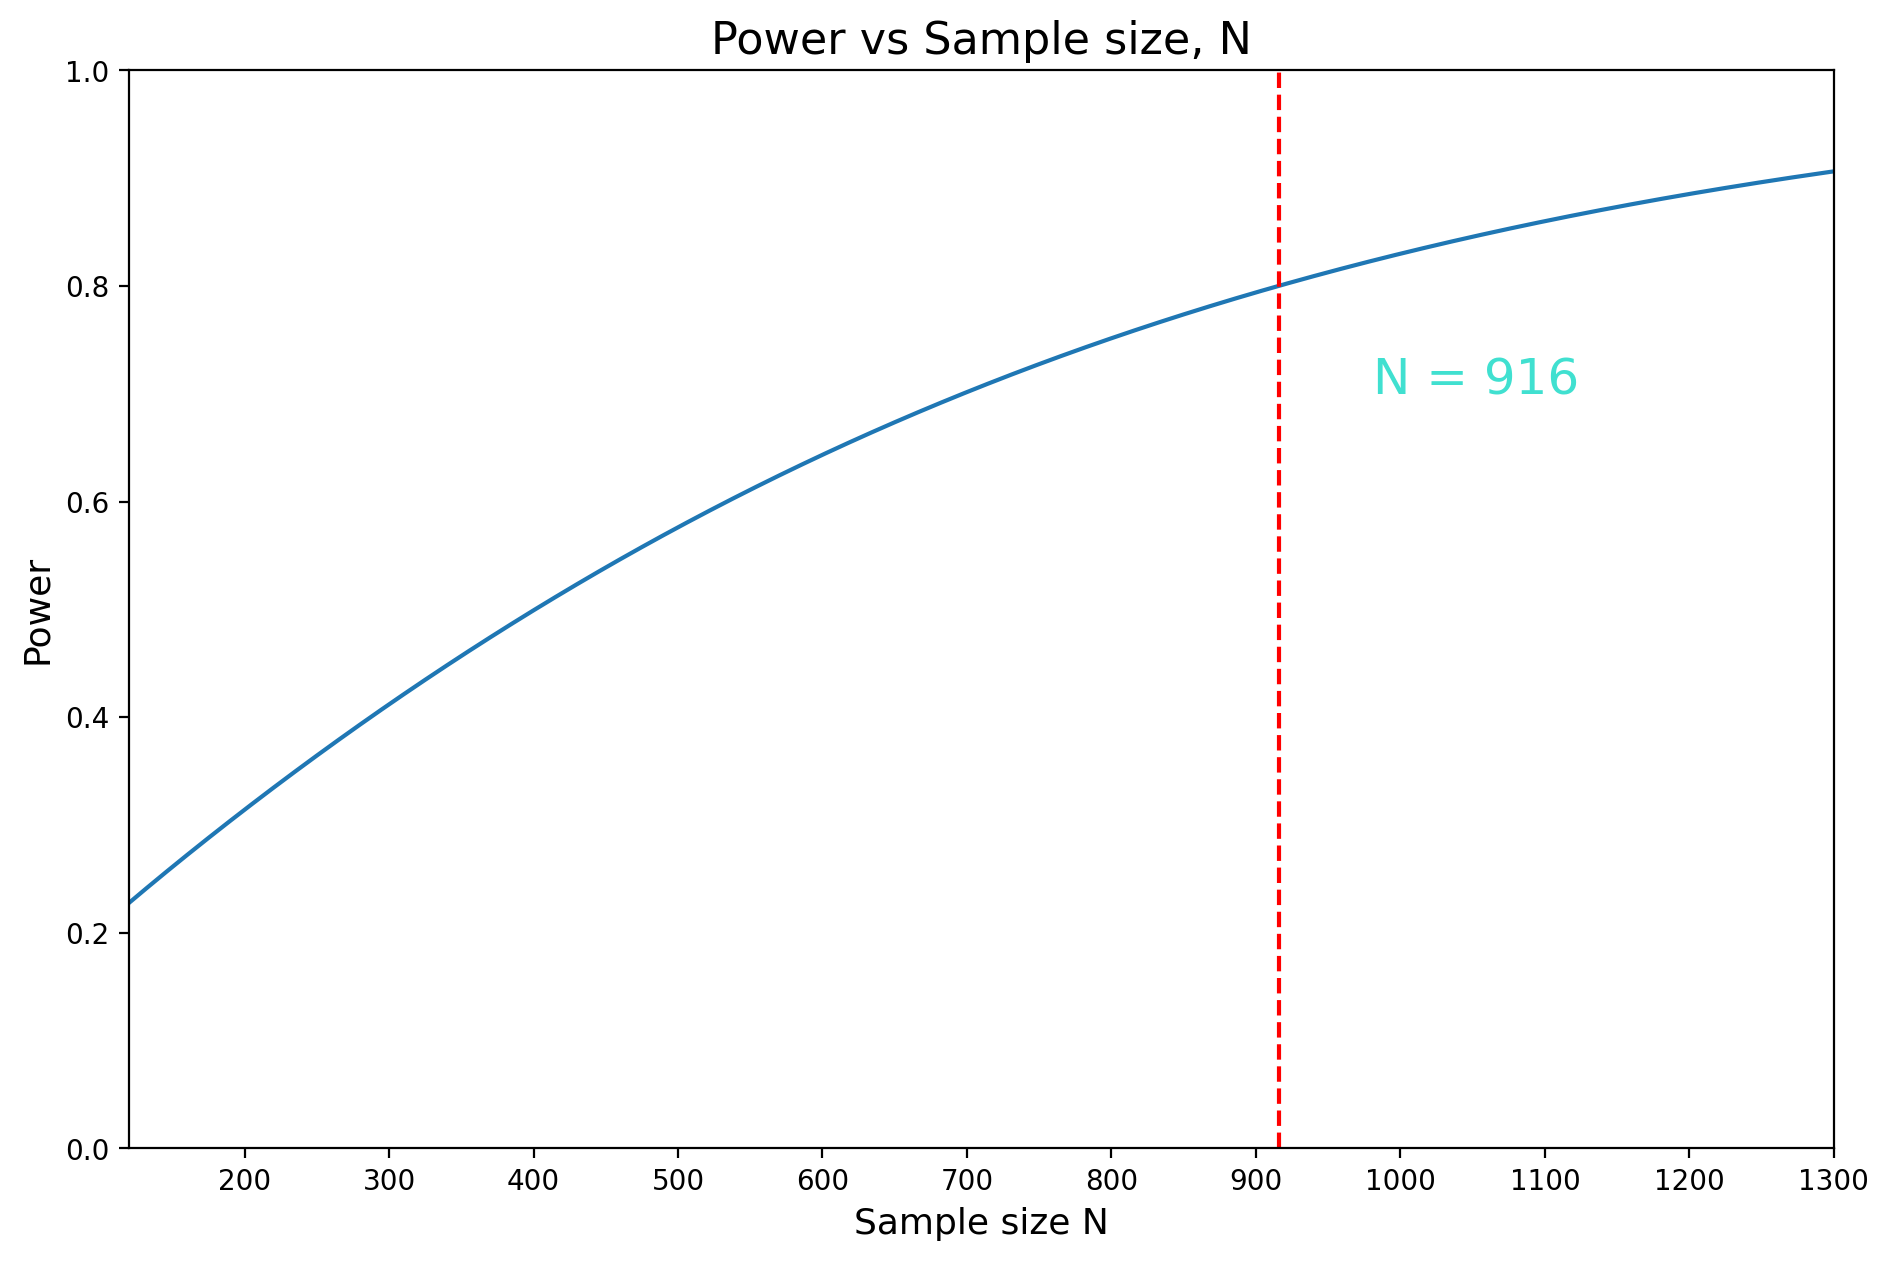

In [ ]:
# Створюємо вісь X
p1, p2 = q1 / n, q2 / n # p1 = 0.269, p2 = 0.322
n_grid = np.arange(100,  1800, 1)

# Рахуємо потужність для різних розмірів вибірки. Вісь Y
power = np.array([my_two_sample_z_power(p2, p1, n, n) for n in n_grid]).squeeze()

# Рахуємо мінімальний розмір вибірки при якому power >= 0.8
#valid_indices = np.where(power >= 0.8)[0]
min_n = n_grid[power >= 0.8].min()

# Створюємо пустий графік та додаємо графік
fig, ax = plt.subplots(figsize = (11, 7))
ax.plot(n_grid[power < 0.91], power[power < 0.91])

# Додаємо вертикальну та горизантальну лінії де power = 0.8
ax.axvline(min_n, color = "red", linestyle = "--")
#ax.axhline(get_stat_power(min_n, mu, mu_alt, alpha), color = "lightblue", linestyle = "--")
ax.text(min_n + 65, 0.7, f"N = {min_n}", color = "turquoise", fontsize = 18)

# Задаємо заголовок, заголовки вісям, xticks, xlim, ylim
ax.set_xticks(np.arange(100, np.round(n_grid[power < 0.91], 2).max(), 100))
ax.set_xlabel("Sample size N", fontsize = 13)
ax.set_ylabel("Power", fontsize = 13)
ax.set_title("Power vs Sample size, N", fontsize = 16)
ax.set_xlim(120, np.round(n_grid[power < 0.91], -2).max())
ax.set_ylim(0, 1)

plt.show()

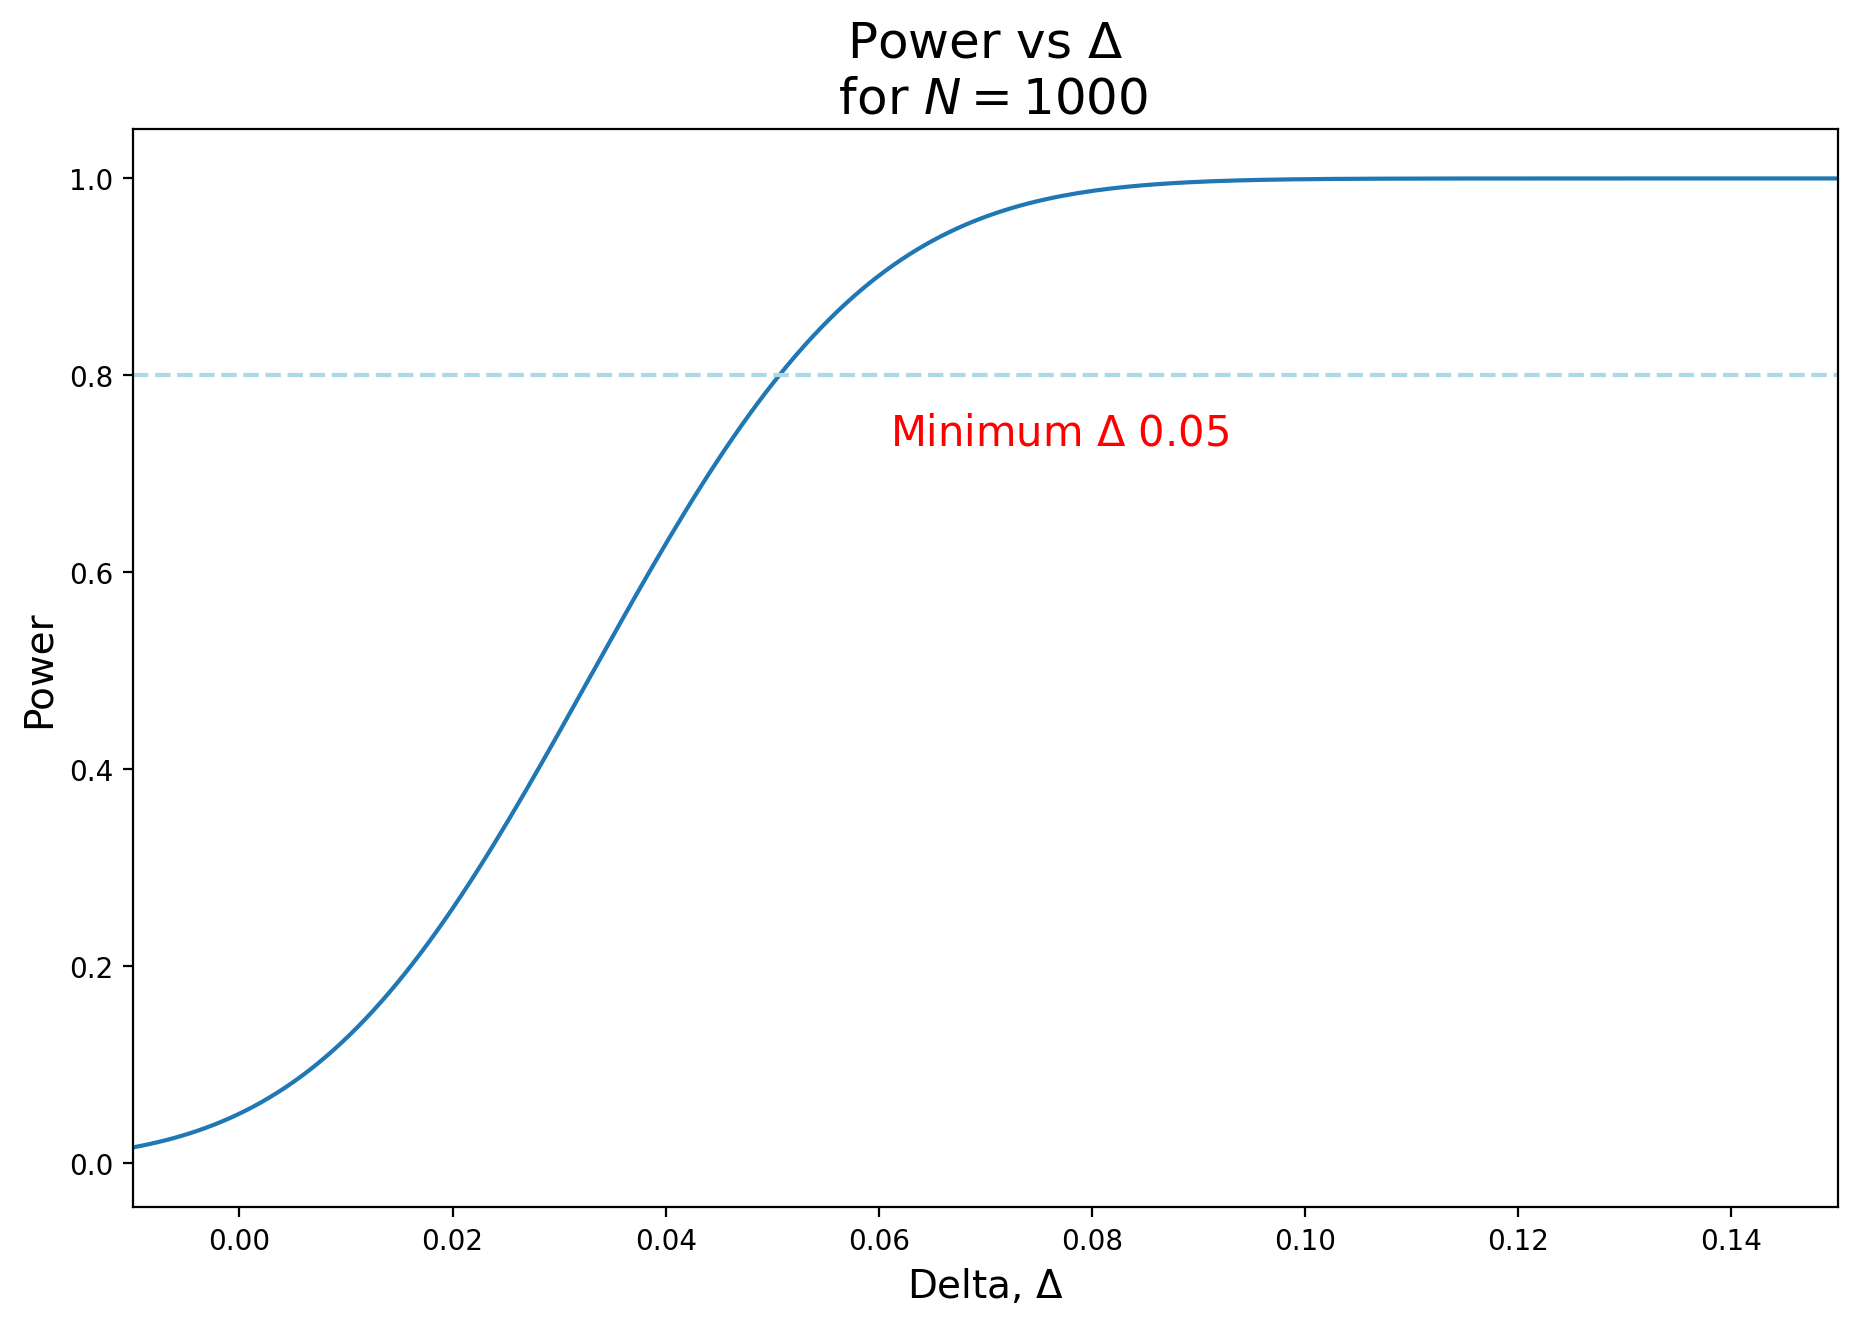

In [ ]:
# Створюємо вісь X
p_2_arr = np.linspace(0.25, 1, 1000)

# Рахуємо для потужність для різних mu_alt
power = np.array([my_two_sample_z_power(p_2, p1, n, n) for p_2 in p_2_arr]).squeeze()
p_2_min = p_2_arr[power >= 0.8].min()

delta_min = p_2_min - p1
delta_min = round(delta_min.item(), 2)

# Cтворюємо пустий графік потім додаємо line plot
fig, ax = plt.subplots(figsize=(11, 7))
ax.plot(p_2_arr - p1, power)

# Додаємо вертикальну та горизантальну лінії де power = 0.8
ax.axhline(0.8, linestyle="--", color="lightblue")

# Створюємо текст про мінімальне альтернативне mu для power = 0.8
ax.text(p_2_arr.min() + 0.08- p1, 0.73, fr"Minimum $\Delta$ {delta_min}", fontsize=15, color="red")

# Задаємо заголовок, заголовки вісям, xlim,
ax.set_title(r"Power vs $\Delta$" + "\n " + r"for $N = 1000$", fontsize = 18)
ax.set_xlabel(r"Delta, $\Delta$", fontsize = 14)
ax.set_ylabel("Power", fontsize = 14)
ax.set_xlim(-0.01, 0.15)

plt.show()

**Розподіл p-value**
* В Lab 2 не вийшов ріномірний розподіл p-value на [0, 1] через те, що там біноміальний дискретний розподіл. А зараз все вийшло.

In [ ]:
np.random.seed(2000)
simulated_experiments_group_1 = binom.rvs(p = mu_1, n = n, size = int(1e5))
np.random.seed(2001)
simulated_experiments_group_2 = binom.rvs(p = mu_1, n = n, size = int(1e5))

p_values = []
is_reject = []
ci_low = []
ci_high = []
for i in range(int(1e5)):
  result = my_z_test(simulated_experiments_group_1[i], n, simulated_experiments_group_2[i], n, alternative="greater")
  p_values.append(result["p_value"])
  ci_low.append(result["ci_low"])
  ci_high.append(result['ci_high'])
p_values = np.array(p_values)
ci_low = np.array(ci_low)
ci_high = np.array(ci_high)
is_reject = np.where(0.05 > p_values, True, False)

In [ ]:
mean_p_values= np.mean(p_values)
print(f"Mean p-value: {mean_p_values:.4f}")

Mean p-value: 0.5008


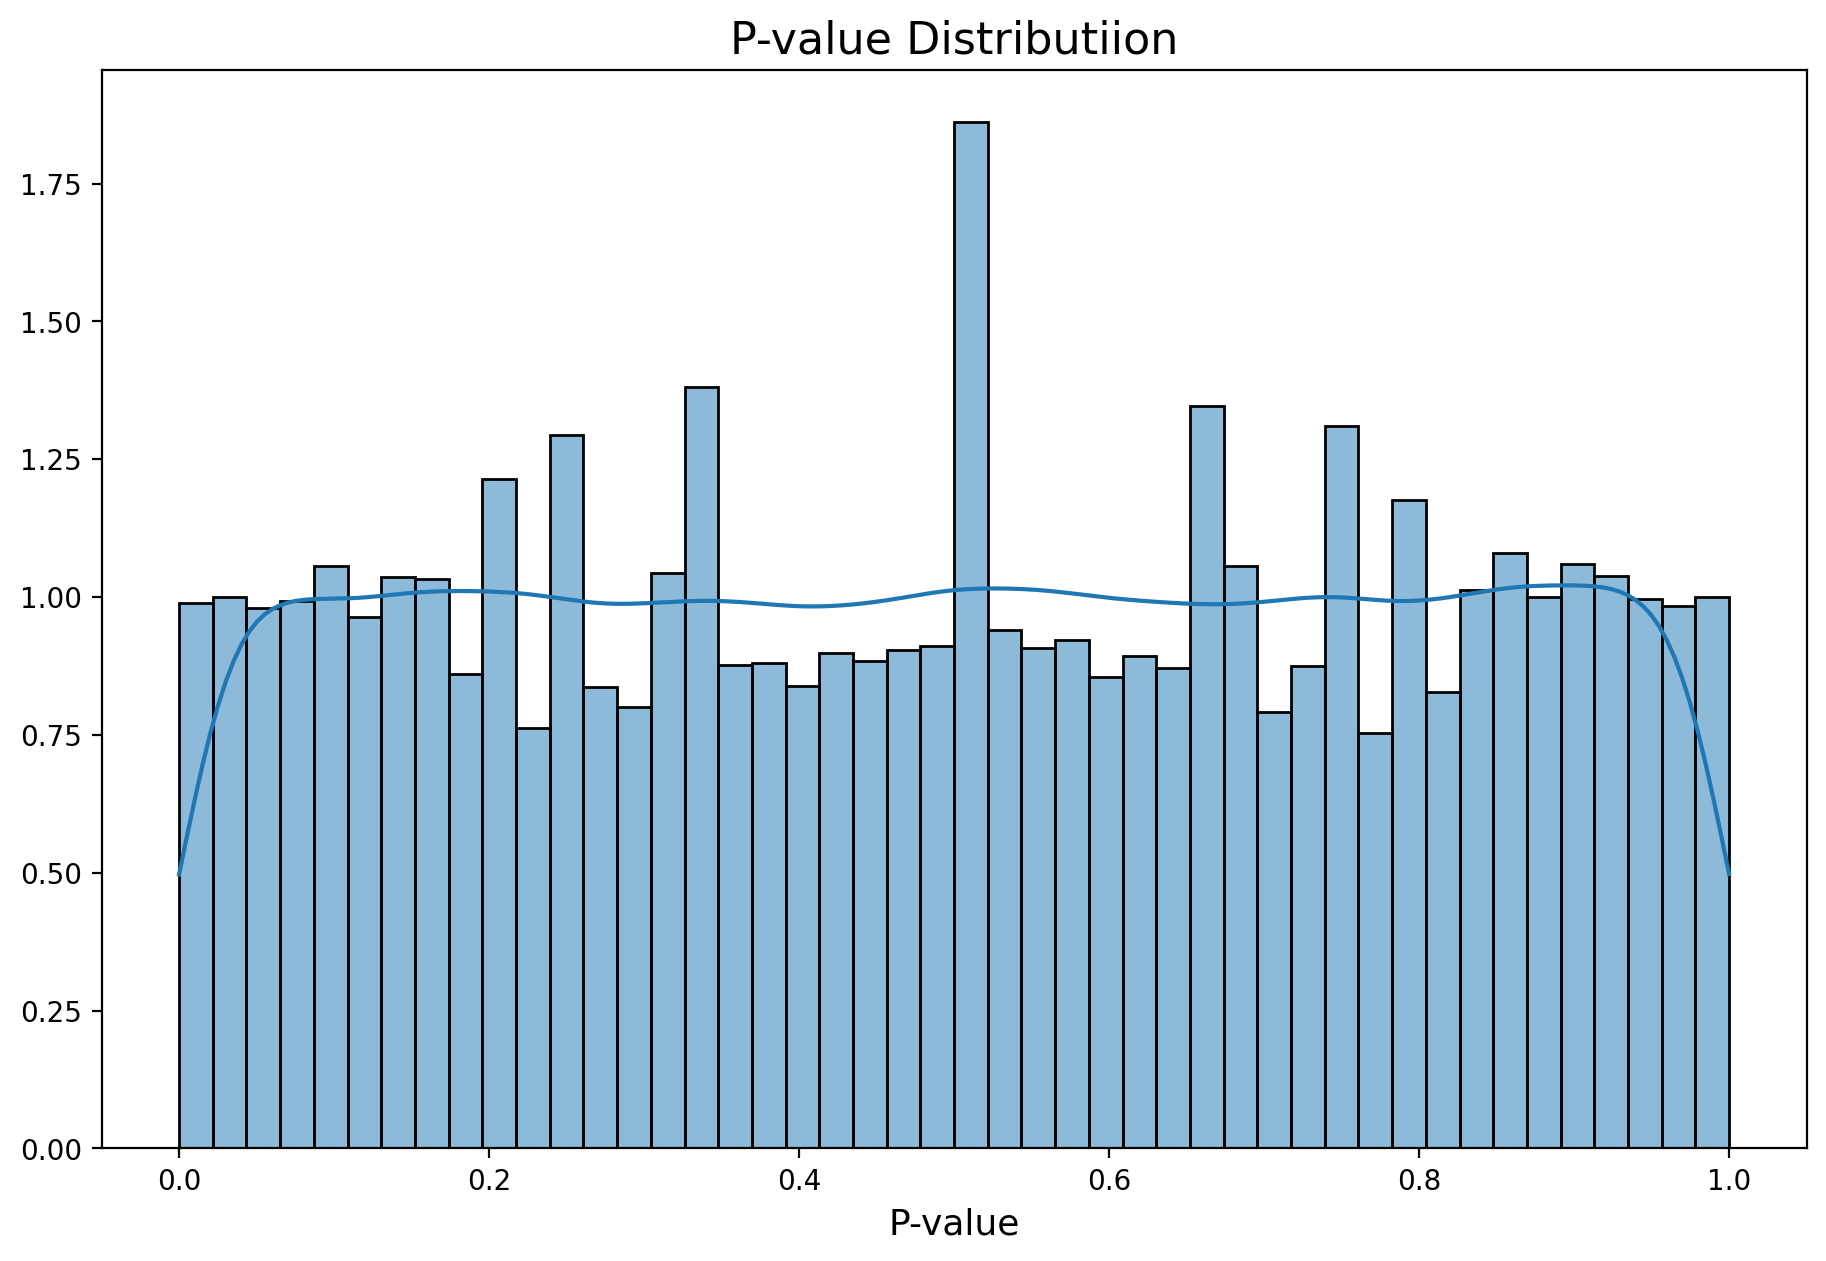

In [ ]:
fig, ax = plt.subplots(figsize = (11,5))

sns.histplot(x = p_values, fill=True, ax = ax, stat='density', kde=True)
ax.set_title("P-value Distributiion", size = 16)
ax.set_xlabel("P-value", size = 13)
ax.set_ylabel("")

plt.show()

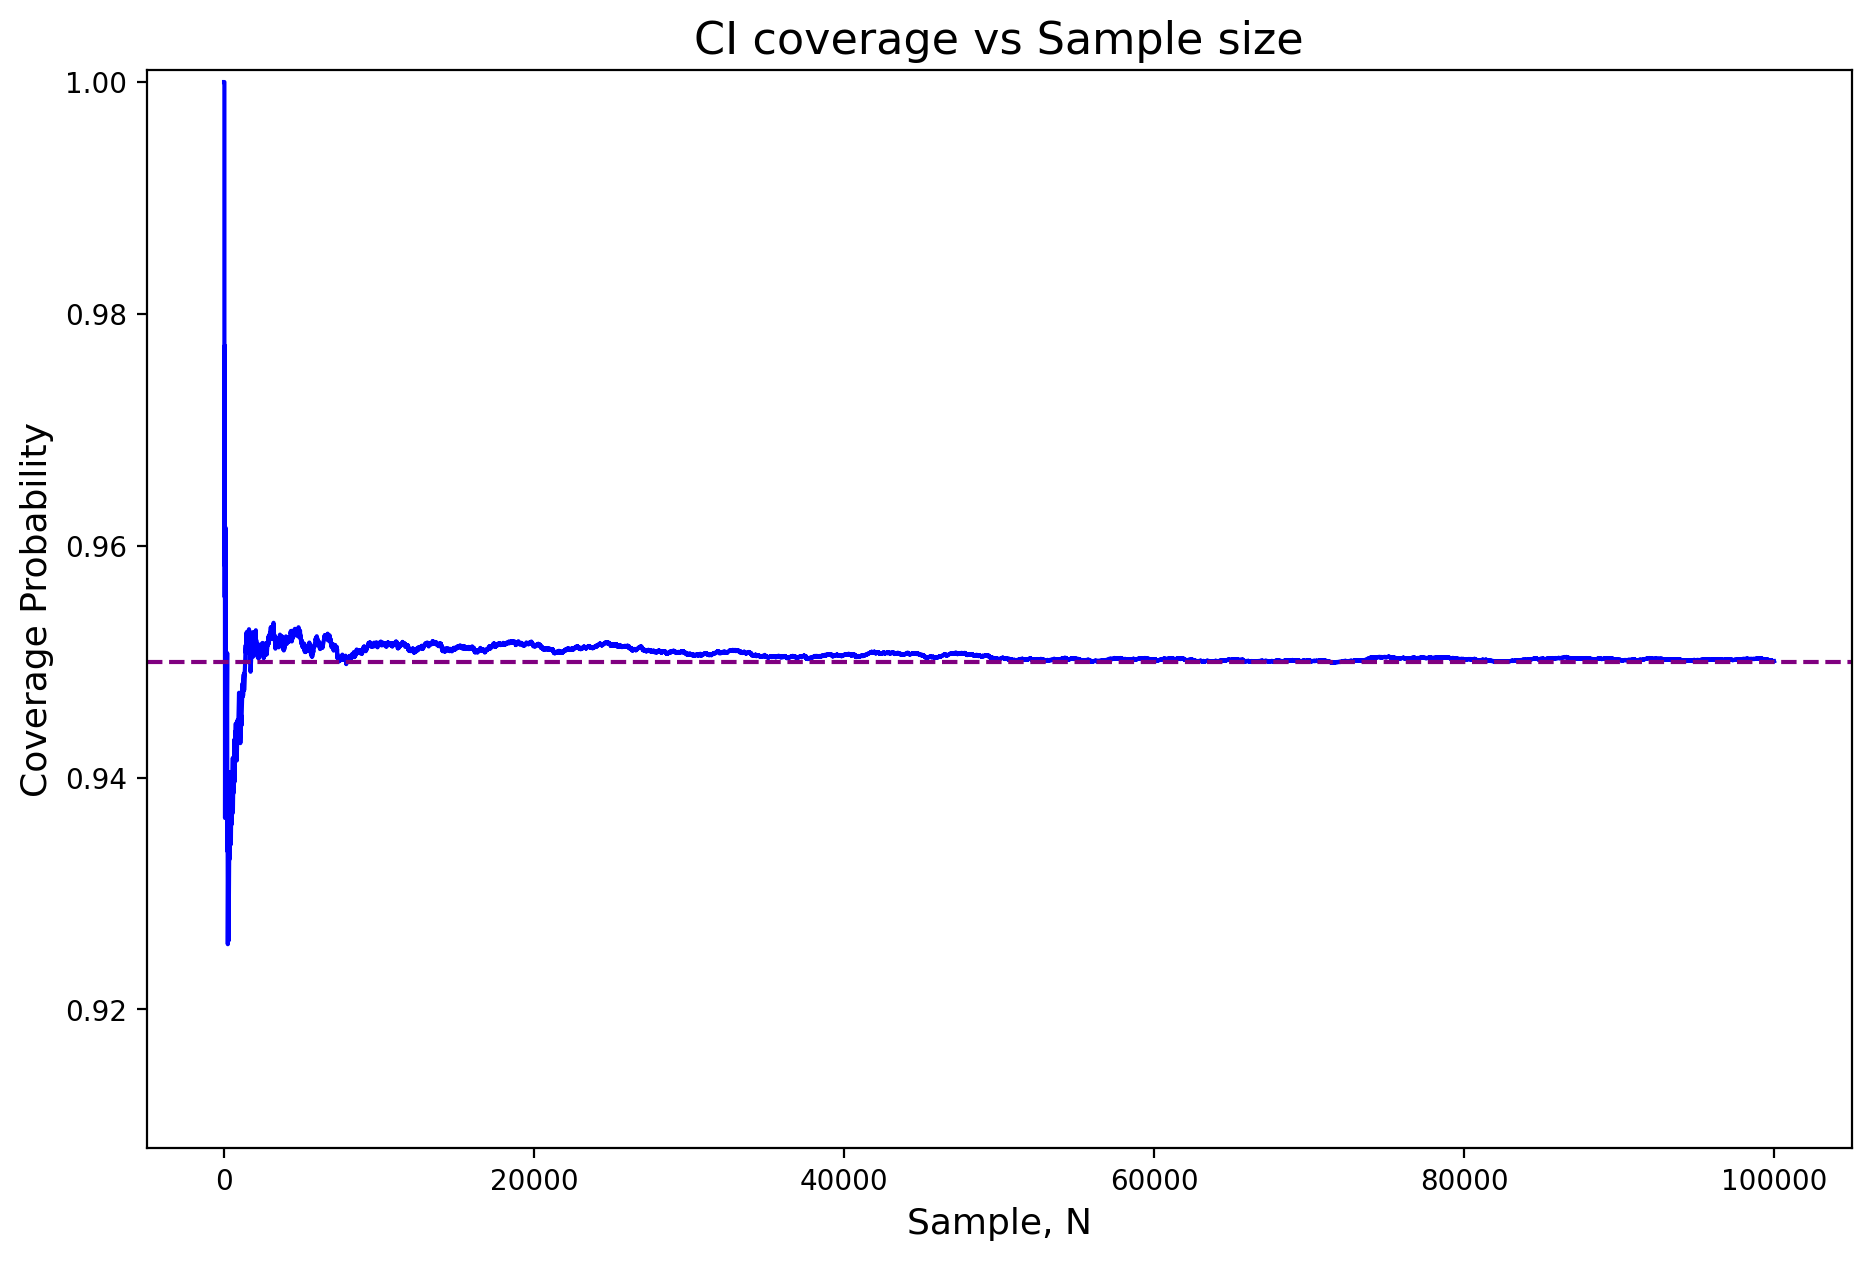

In [ ]:
is_in_cs = ci_low <= 0
coverage_probability = np.cumsum(is_in_cs) / np.arange(1, len(is_in_cs) + 1)
fig, ax = plt.subplots(figsize = (11,7))

ax.plot(coverage_probability, color = "blue")
ax.axhline(0.95, color = "purple", linestyle = "--")

ax.set_title("CI coverage vs Sample size", size = 16)
ax.set_xlabel("Sample, N", size = 13)
ax.set_ylabel("Coverage Probability", size = 13)
ax.set_ylim(0.908, 1.001)

plt.show()

## Memo

**Гіпотези були:**
<div align="center">$H_0$: $p_0$ = $p_1$ &emsp; vs &emsp; $H_0$: $p_0$ < $p_1$</div>


* Estimate 1: 0.269
* Estimate 2: 0.322
* Я обрав правостороній тест, оскільки нас цікавить тільки збільшення
* Confidence Interval : 0.0195 -- 1.0
* Ми бачемо що 0 < CI lower, тому ми маємо достатньо підстав відхилит $H_0$

---
**Рішення:**

Підстави відхилит $H_0$ є, проте різниця, яку ми отрамали маленька

---
A/A тест пройшов без зауважень. Питань щодо коректності нема